Model Name: Mistral-7B
Prompting Technique: Direct Prompting
Parameter Description: parameter: Gender

Overall Accuracy: 0.58
Precision: 0.83
Recall: 0.61
F1 Score: 0.69


/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


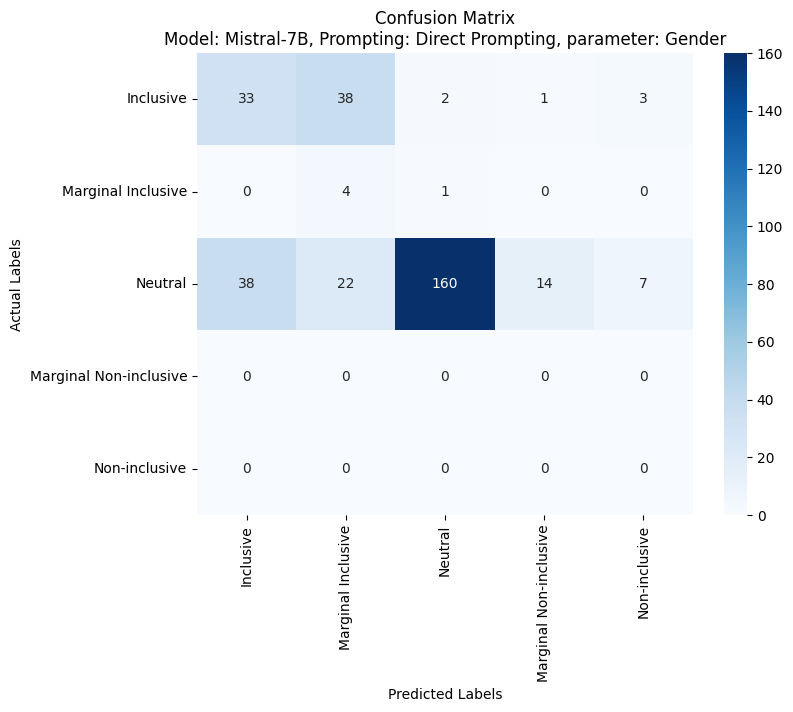

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Parameter-wise Metrics:
                    Label  Precision    Recall  F1 Score
0               Inclusive   0.440000  0.428571  0.434211
1      Marginal Inclusive   0.056338  0.800000  0.105263
2                 Neutral   0.975610  0.663900  0.790123
3  Marginal Non-inclusive   0.000000  0.000000  0.000000
4           Non-inclusive   0.000000  0.000000  0.000000

Label-wise metrics saved to 'parameter_metrics.csv'


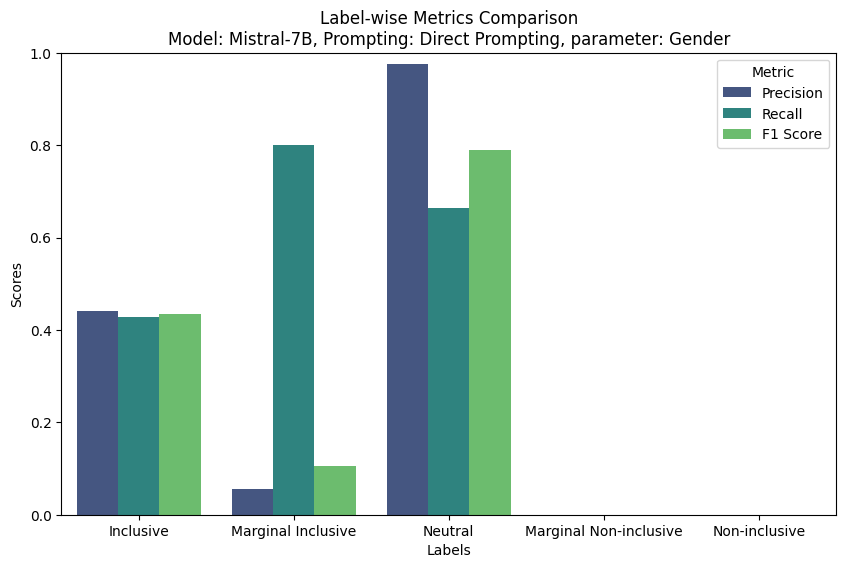

In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Add metadata variables
model_name = "Mistral-7B"
prompting_technique = "Direct Prompting"
parameter_description = "parameter: Gender"

# Print metadata at the start
print(f"Model Name: {model_name}")
print(f"Prompting Technique: {prompting_technique}")
print(f"Parameter Description: {parameter_description}")

# Load the dataset
file_path = "Mistral(DP-G).csv"  # Replace with the actual file path
data = pd.read_csv(file_path)

# Display the first few rows to confirm data structure
# print(data.head())

# Ensure the columns are named as expected
assert 'actual' in data.columns, "Column 'actual' not found in dataset"
assert 'predicted' in data.columns, "Column 'predicted' not found in dataset"

# Check unique values in both columns
# print("Unique values in 'actual':", data['actual'].unique())
# print("Unique values in 'predicted':", data['predicted'].unique())

# Define the labels for evaluation
labels = ['Inclusive', 'Marginal Inclusive', 'Neutral', 'Marginal Non-inclusive', 'Non-inclusive']

data['actual'] = data['actual'].astype(str)
data['predicted'] = data['predicted'].astype(str)

# Calculate accuracy
accuracy = accuracy_score(data['actual'], data['predicted'])
print(f"\nOverall Accuracy: {accuracy:.2f}")

# Calculate precision, recall, and F1 score
precision = precision_score(data['actual'], data['predicted'], labels=labels, average='weighted')
recall = recall_score(data['actual'], data['predicted'], labels=labels, average='weighted')
f1 = f1_score(data['actual'], data['predicted'], labels=labels, average='weighted')

print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# Create a confusion matrix
conf_matrix = confusion_matrix(data['actual'], data['predicted'], labels=labels)

# Plot the heatmap with metadata title
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix\nModel: {model_name}, Prompting: {prompting_technique}, {parameter_description}")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.show()

# Compute metrics for each label
precision_per_class = precision_score(data['actual'], data['predicted'], labels=labels, average=None)
recall_per_class = recall_score(data['actual'], data['predicted'], labels=labels, average=None)
f1_per_class = f1_score(data['actual'], data['predicted'], labels=labels, average=None)

# Create a DataFrame for parameter-wise metrics
metrics_per_class = pd.DataFrame({
    "Label": labels,
    "Precision": precision_per_class,
    "Recall": recall_per_class,
    "F1 Score": f1_per_class
})

# Display the table
print("\nParameter-wise Metrics:")
print(metrics_per_class)

# Save the table to a CSV file
metrics_per_class.to_csv("parameter_metrics.csv", index=False)
print("\nLabel-wise metrics saved to 'parameter_metrics.csv'")

# Bar plot for parameter-wise metrics
metrics_per_class_melted = metrics_per_class.melt(id_vars="Label", var_name="Metric", value_name="Score")

plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_per_class_melted, x="Label", y="Score", hue="Metric", palette="viridis")
plt.title(f"Label-wise Metrics Comparison\nModel: {model_name}, Prompting: {prompting_technique}, {parameter_description}")
plt.xlabel("Labels")
plt.ylabel("Scores")
plt.ylim(0, 1)
plt.legend(title="Metric")
plt.show()